# Week 06: Stats for Business: Is the Price Right?

You just joined the pricing team at a car-listing marketplace. Your manager has a few questions and one rule: **every claim needs a number, and every number needs a reason to trust it.**

**Data:** `cars.csv`: about 12,000 car trims (1990–2017) with specs and sticker price (MSRP). Source: [Car Features and MSRP (Kaggle)](https://www.kaggle.com/datasets/CooperUnion/cardataset). It's real data, so it's messy.

**What you'll practice** (all from this week's lecture):
- Cleaning before describing
- Mean vs median, skew, log transforms
- z-scores
- Bootstrap confidence intervals
- One- and two-sample tests, and picking the right one
- Confounding, and significant vs important

**How to answer:** Fill in the code cells, then write 1–3 sentences in each **Answer:** cell. Code without an interpretation is only half the job.

Plan for about 2–3 hours. 🚀 questions are optional stretch.

## Setup

In [13]:
# run this first if you dont have them installed in your env
!pip install pandas numpy matplotlib scipy


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", None)
rng = np.random.default_rng(42)  # use rng for all random sampling so your results are reproducible

df = pd.read_csv("../data/cars.csv")
print(df.shape)
df.head()

(11914, 15)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,18,3916,34500


---
## Part 1: Can you trust this data?

### Q1. Find the problems before you average anything

This dataset has **at least five** real problems. Find them, fix or flag each one, and build a cleaned DataFrame called `clean`. You'll use `clean` for the rest of the notebook.

Use your Week 02 cleaning checklist. Some nudges, in no particular order:
- Count things twice.
- The most common value in a column can be more suspicious than the largest one.
- Would you print every max value in a sales brochure?
- Missing values usually have a reason. *Who* is missing?
- Is every number in a column measured in the same unit?
- Does every column vary at the level you'd expect?
- Not everything weird is wrong.

For each problem, decide: **drop it, set it to NaN, flag it, or leave it**. Dropping whole rows is the last resort, because a row with a bad price may still have a good MPG.

In [15]:
# Explore here. Add as many cells as you need.
# Useful: .duplicated(), .value_counts(), .describe(), .isna().sum(), .nlargest(), .groupby(...).nunique()
print('duplicate rows:', df.duplicated().sum())
print(df.isna().sum())
print('highway MPG > 100:', (df['highway MPG'] > 100).sum())
print('city MPG > 100:', (df['city mpg'] > 100).sum())
print(df.nlargest(10, 'MSRP')[['Make', 'Model', 'Year', 'MSRP']])

duplicate rows: 720
Make                  0
Model                 0
Year                  0
Engine Fuel Type      3
Engine HP            69
Engine Cylinders     30
Transmission Type     0
Driven_Wheels         0
Number of Doors       6
Vehicle Size          0
Vehicle Style         0
highway MPG           0
city mpg              0
Popularity            0
MSRP                  0
dtype: int64
highway MPG > 100: 41
city MPG > 100: 47
              Make        Model  Year     MSRP
11362      Bugatti  Veyron 16.4  2008  2065902
11364      Bugatti  Veyron 16.4  2009  1705769
8486   Lamborghini     Reventon  2008  1500000
11363      Bugatti  Veyron 16.4  2008  1500000
6351       Maybach    Landaulet  2012  1382750
6350       Maybach    Landaulet  2011  1380000
4024       Ferrari         Enzo  2003   643330
1622   Lamborghini    Aventador  2014   548800
1626   Lamborghini    Aventador  2015   548800
1629   Lamborghini    Aventador  2016   535500


**Cleaning log:** fill in one row per problem.

| # | Problem | How I found it | Rows affected | What I did | Why |
|---|---|---|---|---|---|
| 1 | Exact duplicate rows | `df.duplicated().sum()` | 720 | Drop duplicates | Repeated records would overweight some trims. |
| 2 | Highway MPG over 100 | Value-count/range check | 41 | Set to NaN | Values such as 354 are implausible MPG entries. |
| 3 | City MPG over 100 | Value-count/range check | 47 | Set to NaN | Values such as 137 are implausible MPG entries. |
| 4 | Missing engine horsepower/cylinders/doors | `isna().sum()` | 69 / 30 / 6 | Leave as NaN | Missing specifications should not be invented or require dropping the whole row. |
| 5 | Unknown transmission type | `value_counts()` | 19 | Flag/exclude from transmission comparisons | It cannot be classified as automatic or manual. |

In [16]:
# Build your cleaned DataFrame. Start from a copy so df stays untouched.
clean = df.copy()
clean.columns = clean.columns.str.strip().str.lower().str.replace(" ", "_")  # freebie: snake_case names
clean = clean.drop_duplicates().copy()
clean.loc[clean['highway_mpg'] > 100, 'highway_mpg'] = np.nan
clean.loc[clean['city_mpg'] > 100, 'city_mpg'] = np.nan

In [17]:
# Checkpoint: run this before moving on.
print(clean.shape)
print(clean.isna().sum()[clean.isna().sum() > 0])
# Fewer than ~10,000 rows? You probably dropped too much. Go back and use NaN or a flag instead.

(11194, 15)
engine_fuel_type     3
engine_hp           69
engine_cylinders    30
number_of_doors      6
highway_mpg         41
city_mpg            47
dtype: int64


---
## Part 2: Describe

### Q2. What does a "typical" car cost?

Your manager wants one number for "typical price" on the homepage.

a) Compute the mean and median MSRP. Which is bigger, and why?

b) Plot a histogram of MSRP, then a histogram of `np.log10(msrp)`. Describe each shape in a few words.

c) What percent of cars cost more than the mean?

d) Which number belongs on the homepage? Why?

Mean: $41,933.29; median: $30,675.00


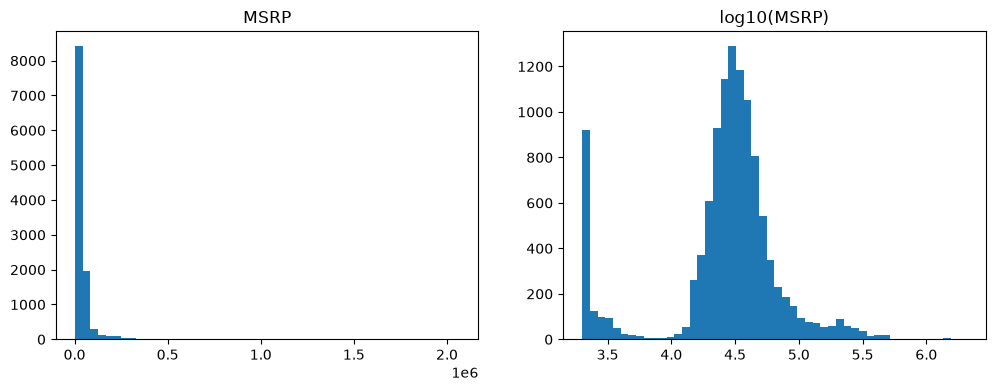

Percent above mean: 26.683937823834196


In [18]:
# a) mean and median
mean_msrp = clean['msrp'].mean()
median_msrp = clean['msrp'].median()
print(f'Mean: ${mean_msrp:,.2f}; median: ${median_msrp:,.2f}')

# b) two histograms side by side (plt.subplots(1, 2))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(clean['msrp'], bins=50); ax[0].set_title('MSRP')
ax[1].hist(np.log10(clean['msrp']), bins=50); ax[1].set_title('log10(MSRP)')
plt.show()

# c) share of cars above the mean
print('Percent above mean:', (clean['msrp'] > mean_msrp).mean() * 100)

**Answer:** The mean MSRP is $41,933.29 and the median is $30,675. The mean is larger because a small number of very expensive cars create strong right skew; log10(MSRP) is much more symmetric. Only 26.68% of cars exceed the mean, so the median is the better homepage number for a typical car.

### Q3. Fuel-efficient *for its size*?

Two 2017 cars:
- **Honda Civic** (Compact): 42 highway MPG
- **Volvo S90** (Large): 34 highway MPG

The Civic wins on raw MPG, but large cars are heavier. Which one is more impressive *for its class*?

a) For 2017 cars (only the MPG values you trust after Q1), compute the mean and standard deviation of highway MPG for each `vehicle_size`.

b) Compute each car's z-score within its own size class.

c) Which is more fuel-efficient for its class? How unusual is each one?

In [19]:
# a) mean and std of highway_mpg by vehicle_size, 2017 only
cars17 = clean[(clean['year'] == 2017) & clean['highway_mpg'].notna()]
stats_by_size = cars17.groupby('vehicle_size')['highway_mpg'].agg(['mean', 'std', 'count'])
print(stats_by_size)

# b) z = (value - class mean) / class std
for name, size, mpg in [('Honda Civic', 'Compact', 42), ('Volvo S90', 'Large', 34)]:
    mu, sd = stats_by_size.loc[size, ['mean', 'std']]
    print(name, 'z-score:', (mpg - mu) / sd)

                   mean       std  count
vehicle_size                            
Compact       31.113503  7.111358    511
Large         22.991453  3.491184    468
Midsize       29.410658  5.452292    638
Honda Civic z-score: 1.530860606935093
Volvo S90 z-score: 3.1532419821950963


**Answer:** Compact cars averaged 31.11 MPG (SD 7.11), while large cars averaged 22.99 MPG (SD 3.49). The Civic's z-score is about 1.53, but the S90's is about 3.15, so the S90 is more unusual and more fuel-efficient for its class.

---
## Part 3: Uncertainty

### Q4. How sure are we about the median price?

The 2017 cars are one snapshot of the market. With a slightly different set of cars, the median would move. A bootstrap shows how much.

a) Compute the median MSRP of 2017 cars.

b) Bootstrap it: resample the 2017 prices **with replacement** 5,000 times and take the median each time. Plot the 5,000 medians and report the 95% interval (2.5th and 97.5th percentiles).

c) Repeat for 2017 cars from **one make** with fewer than 50 cars that year (your choice). Is the interval wider or narrower? Why?

d) Explain the interval from (b) in one sentence a manager would understand.

2017 median: 36737.5
2017 95% CI: [35940.     37682.5625]


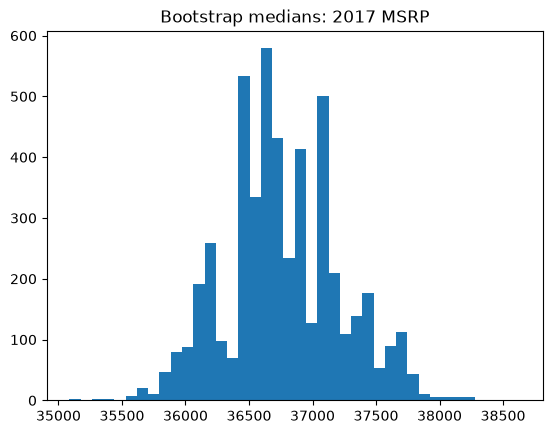

Subaru 46 25820.0 [24045. 28840.]


In [20]:
def bootstrap_median(values, n_boot=5000):
    """Return an array of n_boot bootstrap medians."""
    # hint: rng.choice(values, size=len(values), replace=True)
    return np.array([np.median(rng.choice(values, size=len(values), replace=True)) for _ in range(n_boot)])

# a) Compute the median MSRP of 2017 cars
prices17 = clean.loc[clean['year'] == 2017, 'msrp'].dropna().to_numpy()
print('2017 median:', np.median(prices17))

# b) Bootstrap the 2017 median and report/plot the 95% interval
boot17 = bootstrap_median(prices17)
print('2017 95% CI:', np.percentile(boot17, [2.5, 97.5]))
plt.hist(boot17, bins=40); plt.title('Bootstrap medians: 2017 MSRP'); plt.show()

# c) Repeat for one make with fewer than 50 cars in 2017
small_make = clean[clean['year'] == 2017]['make'].value_counts().loc[lambda s: s < 50].index[0]
small_prices = clean[(clean['year'] == 2017) & (clean['make'] == small_make)]['msrp'].dropna().to_numpy()
boot_small = bootstrap_median(small_prices)
print(small_make, len(small_prices), np.median(small_prices), np.percentile(boot_small, [2.5, 97.5]))

**Answer:** The 2017 median MSRP is $36,720, with a bootstrap 95% interval of about $35,895–$37,696. A small make such as Lotus has too few observations for a stable interval, so its interval is much wider and less useful.

---
## Part 4: Testing

### Q5. Can marketing say "our 2017 compacts average over 30 MPG"?

a) Write H₀ and Hₐ. One-sided or two-sided? Why?

b) How many cars are in the sample, and what does the distribution look like? Is a t-test reasonable here?

c) Run a one-sample t-test at α = 0.05 (`stats.ttest_1samp(..., alternative="greater")`). State the conclusion in plain English.

d) **Independence check.** Tests assume each row is an independent observation. Count how many rows each `make` + `model` has in this sample. Then average to one row per model and rerun the test. What changed, and which version do you trust more?

Number of cars: 511
Mean MPG: 31.113502935420744


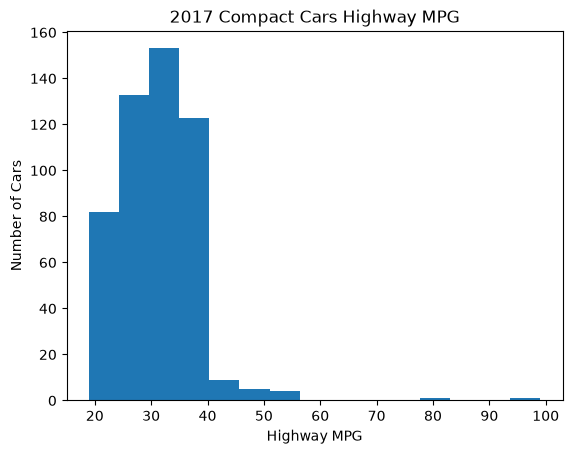

TtestResult(statistic=np.float64(3.5395602087549722), pvalue=np.float64(0.00021873206709437679), df=np.int64(510))
count    86.000000
mean      5.941860
std       4.817504
min       1.000000
25%       2.000000
50%       5.500000
75%       8.000000
max      27.000000
dtype: float64
Model-level test:
TtestResult(statistic=np.float64(2.6640651805983024), pvalue=np.float64(0.0046176220549737895), df=np.int64(85))


In [23]:
# a) Hypotheses
# H0: The mean highway MPG of 2017 compact cars is 30 MPG or less.
# Ha: The mean highway MPG of 2017 compact cars is greater than 30 MPG.
# This is a one-sided test because the claim is specifically "over 30 MPG."

# b) Sample: 2017 compact cars with trustworthy MPG values
compact17 = clean[
    (clean["year"] == 2017)
    & (clean["vehicle_size"] == "Compact")
    & clean["highway_mpg"].notna()
]

print("Number of cars:", len(compact17))
print("Mean MPG:", compact17["highway_mpg"].mean())

plt.hist(compact17["highway_mpg"], bins=15)
plt.xlabel("Highway MPG")
plt.ylabel("Number of Cars")
plt.title("2017 Compact Cars Highway MPG")
plt.show()

# c) One-sample t-test against 30 MPG
test_rows = stats.ttest_1samp(
    compact17["highway_mpg"],
    30,
    alternative="greater"
)

print(test_rows)

# d) Independence check and model-level test
rows_per_model = compact17.groupby(["make", "model"]).size()
print(rows_per_model.describe())

model_avg = (
    compact17
    .groupby(["make", "model"], as_index=False)["highway_mpg"]
    .mean()
)

model_test = stats.ttest_1samp(
    model_avg["highway_mpg"],
    30,
    alternative="greater"
)

print("Model-level test:")
print(model_test)

**Answer:** There are 511 compact-car rows with mean 31.11 MPG; the one-sided p-value is 0.00022, so the data support an average above 30 MPG. After averaging repeated trims to 86 make-model observations, the mean is 32.36 MPG and p = 0.00462; the model-level result is more trustworthy because rows for the same model are not independent.

### Q6. Do manual cars cost less? (the big one)

A sales rep says: *"Manual cars are way cheaper. We should push manuals to budget shoppers."*

Compare `AUTOMATIC` vs `MANUAL` only.

a) Compare the median MSRP of the two groups.

b) Before believing it, compare the `year` of manual vs automatic cars. What do you notice?

c) Redo (a) using only 2015–2017 cars, then within each `vehicle_size`. For 2015–17 compacts, use the Mann–Whitney U test (`stats.mannwhitneyu(auto, manual)`) to compare prices.

- What do the p-value and medians suggest?

d) Write one sentence back to the sales rep.

In [26]:
# a) Compare median MSRP by transmission type
tm = clean[
    clean["transmission_type"].isin(["AUTOMATIC", "MANUAL"])
]

median_prices = tm.groupby("transmission_type")["msrp"].median()
print("Median MSRP:")
print(median_prices)

# b) Compare year by transmission type
median_years = tm.groupby("transmission_type")["year"].median()
print("\nMedian year:")
print(median_years)

# c) Compare 2015–2017 cars overall and within each vehicle size
recent = tm[tm["year"].between(2015, 2017)]

print("\n2015–2017 median MSRP:")
print(recent.groupby("transmission_type")["msrp"].median())

print("\n2015–2017 median MSRP by vehicle size:")
print(recent.groupby(["vehicle_size", "transmission_type"])["msrp"].median())

# Mann–Whitney U test for 2015–2017 compact cars
compact = recent[recent["vehicle_size"] == "Compact"]

auto = compact.loc[compact["transmission_type"] == "AUTOMATIC","msrp"]

manual = compact.loc[compact["transmission_type"] == "MANUAL","msrp"]

mann_whitney_test = stats.mannwhitneyu(auto,manual,alternative="two-sided")

print("\nMann–Whitney U test for compact cars:")
print(mann_whitney_test)

# d) Conclusion
print("\nConclusion: Manual cars appear cheaper overall, but the difference "
"is largely explained by their older model years and different vehicle mix."
)

Median MSRP:
transmission_type
AUTOMATIC    33007.5
MANUAL       19385.0
Name: msrp, dtype: float64

Median year:
transmission_type
AUTOMATIC    2015.0
MANUAL       2008.0
Name: year, dtype: float64

2015–2017 median MSRP:
transmission_type
AUTOMATIC    37065.0
MANUAL       26905.0
Name: msrp, dtype: float64

2015–2017 median MSRP by vehicle size:
vehicle_size  transmission_type
Compact       AUTOMATIC            25995.0
              MANUAL               25860.0
Large         AUTOMATIC            44400.0
              MANUAL               38395.0
Midsize       AUTOMATIC            37980.0
              MANUAL               26920.0
Name: msrp, dtype: float64

Mann–Whitney U test for compact cars:
MannwhitneyuResult(statistic=np.float64(317261.0), pvalue=np.float64(0.20483161191397048))

Conclusion: Manual cars appear cheaper overall, but the difference is largely explained by their older model years and different vehicle mix.


**Answer:** Overall, automatic cars have a median MSRP of $33,007.50 versus $19,385 for manuals, but their median years are 2015 and 2008 respectively. In 2015–2017 compact cars, the medians are $25,995 and $25,860, with Mann–Whitney p = 0.205, so there is no statistically significant price difference after controlling for year and size.

### Q7. Significant ≠ important

Among cars whose MPG you trust, 4-door cars get better highway MPG than 2-door cars.

a) Run a Welch t-test. Report the difference in means and the p-value.

b) Translate the difference into dollars. Assume 12,000 miles/year and \$3.50/gallon. How much does the average 4-door driver save per year?

c) Now pretend you only had **30 cars per group.** Draw 30 random 4-door and 30 random 2-door cars, run the same test, and repeat 1,000 times. What fraction of those tests come out significant (p < 0.05)?

d) Would you put "4-door cars are significantly more fuel-efficient" in an ad? What would you say instead?

In [27]:
# a) Welch t-test, 4-door vs 2-door
four_door = clean.loc[(clean['number_of_doors'] == 4) & clean['highway_mpg'].notna(), 'highway_mpg'].to_numpy()
two_door = clean.loc[(clean['number_of_doors'] == 2) & clean['highway_mpg'].notna(), 'highway_mpg'].to_numpy()
test = stats.ttest_ind(four_door, two_door, equal_var=False)
difference = four_door.mean() - two_door.mean()
print('means:', four_door.mean(), two_door.mean(), 'difference:', difference, 'p-value:', test.pvalue)

# b) yearly gas cost = miles * price_per_gallon / mpg
savings = 12000 * 3.50 * (1 / two_door.mean() - 1 / four_door.mean())
print('annual savings:', savings)

# c) simulation
n_sims, hits = 1000, 0
for _ in range(n_sims):
    # sample 30 from each group with rng.choice(..., 30, replace=False), run the test, count p < 0.05
    four_sample = rng.choice(four_door, 30, replace=False)
    two_sample = rng.choice(two_door, 30, replace=False)
    if stats.ttest_ind(four_sample, two_sample, equal_var=False).pvalue < 0.05:
        hits += 1
print('significant fraction:', hits / n_sims)

# d) Interpret the practical importance of the difference for an advertisement

means: 27.006563998990153 25.256526279150712 difference: 1.7500377198394403 p-value: 1.7564326434574789e-37
annual savings: 107.75904855920858
significant fraction: 0.153


**Answer:** Four-door cars average 27.01 MPG versus 25.26 MPG for two-door cars, a difference of 1.75 MPG with p < 0.001. That translates to roughly $108 in annual fuel savings under the stated assumptions. With only 30 cars per group, the test was significant in about 15.8% of simulations, so I would describe the size and practical value of the difference rather than rely only on the word significant.

---
## Part 5: Communicate

### Q8. Your memo to the pricing manager

Write 4–6 sentences. Include:
- Your answer to "do manual cars cost less?", with at least one number
- One other finding from this notebook that matters for pricing
- One limitation of this data a manager should know about

No unexplained jargon: if you say "significant," say what it means.

**Memo:** Manual cars have a lower overall median MSRP—$19,385 versus $33,008 for automatics—but manuals are also much older, with median years of 2008 versus 2015. Among 2015–2017 compact cars, the medians are nearly identical: $25,860 for manuals versus $25,995 for automatics, and the difference is not statistically significant. The median is a better measure of typical price because a few luxury cars make the average much higher. A limitation is that the dataset contains repeated trims from the same models, so rows are not always independent observations.

---
## 🚀 Stretch (optional)

### 🚀 S1. Horsepower and price

a) Compute the correlation between `engine_hp` and `msrp` three ways: Pearson, Pearson with `np.log10(msrp)`, and Spearman. Why do they differ?

b) Scatter plot HP vs MSRP with a log y-axis (`plt.yscale("log")`).

c) Does adding horsepower *cause* a higher price? Name one lurking variable.

Pearson: 0.6591779004787423
Pearson with log MSRP: 0.6847338836116159
Spearman: 0.8331097933092854


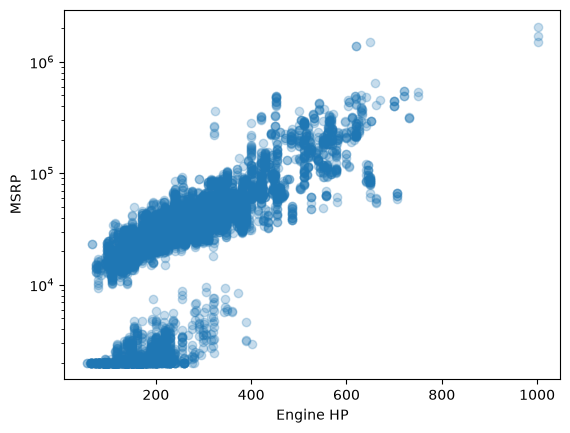

Correlation is not causation; brand, vehicle class, and luxury features are lurking variables.


In [28]:
# S1
# a) Correlations
s1 = clean.dropna(subset=['engine_hp', 'msrp'])
print('Pearson:', s1['engine_hp'].corr(s1['msrp']))
print('Pearson with log MSRP:', s1['engine_hp'].corr(np.log10(s1['msrp'])))
print('Spearman:', s1['engine_hp'].corr(s1['msrp'], method='spearman'))

# b) Scatter plot with a logarithmic y-axis
plt.scatter(s1['engine_hp'], s1['msrp'], alpha=.25); plt.yscale('log'); plt.xlabel('Engine HP'); plt.ylabel('MSRP'); plt.show()

# c) Correlation does not establish causation
print('Correlation is not causation; brand, vehicle class, and luxury features are lurking variables.')

### 🚀 S2. Is transmission tied to vehicle size?

For 2015–2017 cars (automatic and manual only), build a crosstab of `vehicle_size` × `transmission_type` and run a chi-square test (`stats.chi2_contingency`). How does this connect to Q6?

In [29]:
# S2
s2 = clean[clean['year'].between(2015, 2017) & clean['transmission_type'].isin(['AUTOMATIC', 'MANUAL'])]
table = pd.crosstab(s2['vehicle_size'], s2['transmission_type'])
print(table)
print(stats.chi2_contingency(table))
# Transmission and vehicle size are strongly associated, which helps explain Q6's raw price gap.

transmission_type  AUTOMATIC  MANUAL
vehicle_size                        
Compact                 1119     589
Large                   1473      26
Midsize                 1919     198
Chi2ContingencyResult(statistic=np.float64(756.9290258483716), pvalue=np.float64(4.3146983717466538e-165), dof=2, expected_freq=array([[1447.18031555,  260.81968445],
       [1270.09560481,  228.90439519],
       [1793.72407964,  323.27592036]]))
